# Python for AI — Class 21 (OOP version)
### Neural Networks with PyTorch, using classes

Two parts:
1. **Simple version:** a small network in PyTorch, **no classes**.
2. **OOP version:** the same network, written as **classes**. A class = a **box** that keeps the data and the functions together.

```
  study_hours ──┬────▶ ( neuron 1 ) ──┐
                ├────▶ ( neuron 2 ) ──┼────▶ ( output ) ──▶ predicted Maths mark
  phone_hours ──┴────▶ ( neuron 3 ) ──┘
```

**In Part 2 we make 2 classes:**

| Class | What it does |
|-------|--------------|
| `Net` | the **map**: layers + forward pass |
| `Trainer` | **trains** the map and **guesses** for new data |

Then we use the **same 2 classes** for Maths marks, digits, and car prices (home). Example 3 shows **2 hidden layers** and **sigmoid**.

**Using Colab?** Upload `students_100.csv`, `loans.csv` and `cars.csv` first.

In [1]:
# On your own laptop, install once:  pip install torch scikit-learn
import pandas as pd                                    # read the CSV file into a table
import matplotlib.pyplot as plt                        # draw charts (the loss curves)
import torch                                           # PyTorch: tensors + training
from torch import nn                                   # nn = "neural network": layers, ReLU, loss functions
from sklearn.model_selection import train_test_split   # split data into train / validation / test
from sklearn.preprocessing import StandardScaler       # scaling (used in Part 2, not in Part 1)
from sklearn.metrics import mean_absolute_error        # MAE: how wrong, on average
from sklearn.datasets import load_digits               # the handwritten digits pictures (Example 2)

# Part 1: A simple network, no classes

The whole idea in one cell:
1. Inputs `X` and real answers `y`.
2. The map: `nn.Sequential` = layers in a row.
3. The training loop: **guess → how wrong → clear → blame (backprop) → fix**.
4. Use it for a new student.

X shape: torch.Size([100, 2])   y shape: torch.Size([100, 1])
epoch   0:  loss = 3173.5
epoch  50:  loss = 219.5
epoch 100:  loss = 106.0
epoch 150:  loss = 76.3
epoch 200:  loss = 62.9
epoch 250:  loss = 54.7


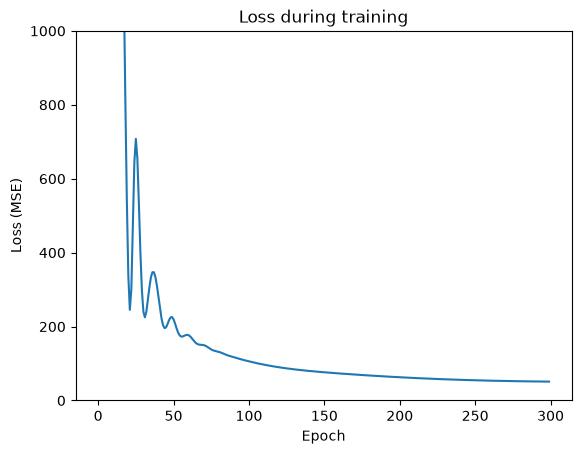

3 study hours, 2 phone hours → 61.2 marks


In [2]:
# 1. inputs and real answers
students = pd.read_csv("students_100.csv")      # read the file: one row per student

X = torch.tensor(                               # make a tensor (PyTorch's array) for the inputs
    students[["study_hours", "phone_hours"]].values,   # 2 columns → .values = only the numbers (a NumPy array)
    dtype=torch.float32,                        # decimal numbers: networks always use decimals
)
y = torch.tensor(                               # make a tensor for the real answers
    students[["maths"]].values,                 # [["maths"]] (2 brackets) = 1 column, shape (100, 1)
    dtype=torch.float32,
)
print("X shape:", X.shape, "  y shape:", y.shape)   # (100, 2) and (100, 1)

# 2. the map: 2 inputs → 3 hidden (ReLU) → 1 output
torch.manual_seed(42)                           # the same "random" starting weights for everyone
model = nn.Sequential(                          # put the layers in a row, left → right
    nn.Linear(2, 3),                            # 2 inputs → 3 hidden neurons (6 weights + 3 biases)
    nn.ReLU(),   
    nn.Linear(3, 4),                            # 2 inputs → 3 hidden neurons (6 weights + 3 biases)
    nn.ReLU(),                                                                          # activation: negative → 0
    nn.Linear(4, 1),                            # 3 hidden neurons → 1 output (3 weights + 1 bias)
)
loss_fn = nn.MSELoss()                          # loss = average of (guess − real)²
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)   # the one who changes the weights. lr = step size

# 3. training loop
losses = []                                     # save the loss of every epoch, to draw it later
for epoch in range(300):                        # 300 epochs = 300 rounds through all the students
    guess = model(X)                            # 1. guess: forward pass for all 100 students
    loss = loss_fn(guess, y)                    # 2. how wrong: one number
    optimizer.zero_grad()                       # 3. clear old blame (gradients from the last round)
    loss.backward()                             # 4. find blame: backpropagation finds the GRADIENT of every weight                                   #    gradient = which way to change the weight (and how much) to make the loss smaller
    optimizer.step()                            # 5. fix: every weight takes one small step downhill
    losses.append(loss.item())                  # save this epoch's loss (.item() = the number out of the tensor)
    if epoch % 50 == 0:                         # print only every 50 epochs (0, 50, 100 ...)
        print(f"epoch {epoch:3}:  loss = {loss.item():.1f}")   # .item() = take the number out of the tensor

# 4. draw the loss curve: it should go DOWN
plt.plot(losses)                                # x = epoch, y = loss
plt.ylim(0, 1000)                               # zoom in: the first epochs are huge (about 3000)
plt.title("Loss during training")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.show()

# 5. use it
with torch.no_grad():                           # only guessing, no learning: don't track gradients
    new_student = torch.tensor([[3, 2]], dtype=torch.float32)   # 1 student: 3 study hours, 2 phone hours
    print("3 study hours, 2 phone hours →", round(model(new_student).item(), 1), "marks")

### What is a gradient? Why `.values`? Why `Adam`?

**Gradient**
- Remember the **hill in the fog**: we want to reach the bottom (the smallest loss).
- The **gradient** of a weight tells us **which way is downhill** for that weight, and **how steep** it is.
  - gradient **negative** → make the weight **bigger**.
  - gradient **positive** → make the weight **smaller**.
  - gradient **big** → the hill is steep here. gradient **near 0** → we are close to the bottom.
- `loss.backward()` finds the gradient of **all 13 weights and biases** at once (backpropagation).
- `optimizer.step()` uses the gradients to move every weight a small step downhill.
- After training, look at one: `model[0].weight.grad` (one gradient for each weight).

**`.values`**
- `students[["study_hours", "phone_hours"]]` is a **Pandas table**: numbers + column names + row numbers.
- `.values` keeps **only the numbers**, as a NumPy array.
- `torch.tensor(...)` wants plain numbers. So: table → `.values` → tensor.

**Adam or SGD?** Both do the same job: **step downhill**. The difference is the **step size**.

| | SGD | Adam |
|---|---|---|
| Step size | **one fixed** step size for **every** weight | finds a **good step size for each weight by itself** |
| Memory | looks only at this step | remembers the **past steps** (if it went downhill many times, it walks faster) |
| Learning rate | you must find the **right** one, by trying | works well with **many** learning rates |

**On our 100 students (300 epochs, same network):**

| Optimizer | Loss at the end |
|---|---|
| Adam, `lr=0.1` | **51** ✓ |
| SGD, `lr=0.1` | 163 ✗ (stuck: it guesses the average for everybody) |
| SGD, `lr=0.01` | 163 ✗ (stuck) |
| SGD, `lr=0.001` | 64 (OK, but you had to search for this lr) |

**So:** SGD is not wrong. It is the simple, basic method (the one we wrote by hand in the idea class). Adam is **easier**: less searching for the learning rate, and usually faster. That's why most people **start with Adam**.

The loss goes **down**: the network is learning. Now let's write the same thing with **classes**.

# Part 2: The OOP version

## The 2 classes

- `Net` **inherits** from `nn.Module`. This gives it all the PyTorch powers (weights, `.parameters()`, ...).
  - `__init__` = **build** the layers.
  - `forward` = the **forward pass**: data goes left → right.
- `Trainer` keeps the **model**, the **loss** and the **optimizer** together.
  - `fit` = the training loop: **guess → how wrong → clear → blame → fix**.
  - `predict` = guess for new data (with `torch.no_grad()`, no learning).

In [3]:
def to_tensor(a, dtype=torch.float32):
    return torch.tensor(a, dtype=dtype)


class Net(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_outputs):
        super().__init__()                          # start the nn.Module part
        self.hidden = nn.Linear(n_inputs, n_hidden) # input → hidden (weights + biases)
        self.relu = nn.ReLU()                       # activation: negative → 0
        self.output = nn.Linear(n_hidden, n_outputs)# hidden → output

    def forward(self, x):
        return self.output(self.relu(self.hidden(x)))


class Trainer:
    def __init__(self, model, loss_fn, lr):
        self.model = model
        self.loss_fn = loss_fn
        self.optimizer = torch.optim.Adam(model.parameters(), lr=lr)
        self.train_losses, self.val_losses = [], []

    def fit(self, X_train, y_train, X_val, y_val, epochs):
        for epoch in range(epochs):
            loss = self.loss_fn(self.model(X_train), y_train)   # 1. guess + 2. how wrong
            self.optimizer.zero_grad()                          # 3. clear old blame
            loss.backward()                                     # 4. find blame (backprop)
            self.optimizer.step()                               # 5. fix (gradient descent)
            self.train_losses.append(loss.item())
            with torch.no_grad():                               # mock exam: check only
                self.val_losses.append(self.loss_fn(self.model(X_val), y_val).item())

    def predict(self, X):
        with torch.no_grad():
            return self.model(X)

    def plot(self):
        plt.plot(self.train_losses, label="train (homework)")
        plt.plot(self.val_losses, label="validation (mock exam)")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.legend()
        plt.show()

# 🧑‍🏫 Class Problem: guess a student's Maths mark

2 inputs (study hours, phone hours) → 3 hidden neurons → 1 output (the mark).

In [4]:
# 1. data + split (60 / 20 / 20)
students = pd.read_csv("students_100.csv")
X = students[["study_hours", "phone_hours"]].values
y = students["maths"].values
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, random_state=42)

# 2. scale (fit on train only) + tensors
scaler = StandardScaler().fit(X_train)
X_train_t, X_val_t, X_test_t = (to_tensor(scaler.transform(d)) for d in (X_train, X_val, X_test))
y_train_t = to_tensor(y_train).reshape(-1, 1)
y_val_t = to_tensor(y_val).reshape(-1, 1)

# 3. build + train
torch.manual_seed(42)
model = Net(n_inputs=2, n_hidden=3, n_outputs=1)
trainer = Trainer(model, nn.MSELoss(), lr=0.1)
trainer.fit(X_train_t, y_train_t, X_val_t, y_val_t, epochs=300)
print(model)
print("Weights + biases learned:", sum(p.numel() for p in model.parameters()))

# 4. final exam: on average, how many marks wrong?
mae = mean_absolute_error(y_test, trainer.predict(X_test_t).numpy().ravel())
print("Wrong by", round(mae, 1), "marks on average")

# 5. use it
guess = trainer.predict(to_tensor(scaler.transform([[3, 2]])))
print("3 study hours, 2 phone hours →", round(guess.item(), 1), "marks")

Net(
  (hidden): Linear(in_features=2, out_features=3, bias=True)
  (relu): ReLU()
  (output): Linear(in_features=3, out_features=1, bias=True)
)
Weights + biases learned: 13
Wrong by 6.1 marks on average
3 study hours, 2 phone hours → 62.4 marks


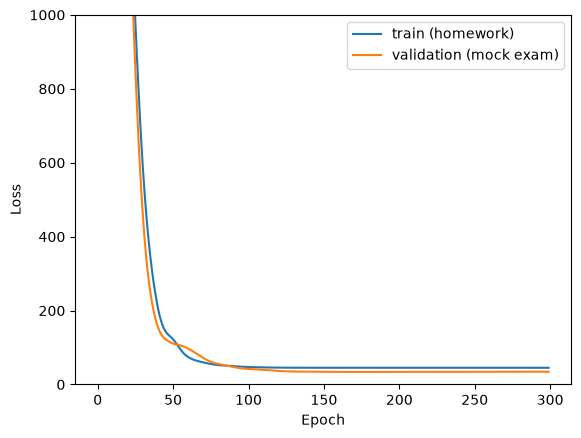

In [5]:
plt.ylim(0, 1000)      # zoom in: the first epochs are huge
trainer.plot()

Both lines go down and stay close: ✓ learning well.

# 🧑‍🏫 Example 2: read handwritten digits

**Same 2 classes**, only 3 things change:

| | Maths marks | Digits |
|---|---|---|
| Inputs | 2 | **64** (pixels) |
| Outputs | 1 | **10** (one score per digit) |
| Loss | `nn.MSELoss` | `nn.CrossEntropyLoss` |

This is the power of OOP: **write the class once, use it many times**.

### Look at the data first: what do the pictures look like?

Each picture is only **8 × 8 = 64 pixels**. Every pixel is a number: **0 = white** (no ink), **16 = black** (full ink).

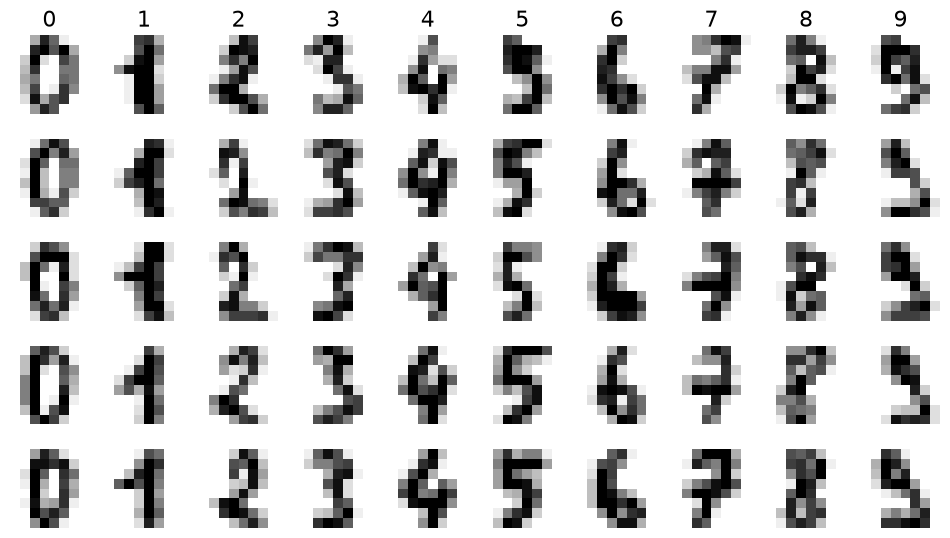

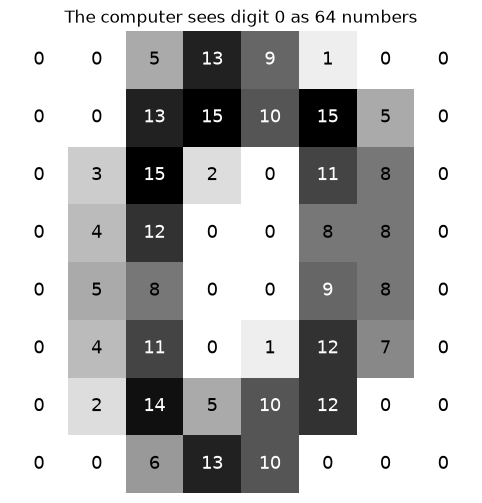

In [6]:
import numpy as np
from sklearn.datasets import load_digits

digits = load_digits()                                  # 1797 small pictures of handwritten digits

# 1. 5 examples of each digit, 0 to 9
fig, axes = plt.subplots(5, 10, figsize=(12, 6.5))      # 5 rows × 10 columns of small pictures
for digit in range(10):                                 # one column for each digit 0..9
    positions = np.where(digits.target == digit)[0][:5] # the first 5 pictures of this digit
    for row, i in enumerate(positions):
        ax = axes[row, digit]
        ax.imshow(digits.images[i], cmap="gray_r")      # draw the 8 × 8 grid (0 = white, 16 = black)
        ax.axis("off")                                  # hide the axis numbers
        if row == 0:
            ax.set_title(digit, fontsize=16)            # the digit on top of each column
plt.show()

# 2. What the computer sees: one picture with its 64 numbers
first = digits.images[0].astype(int)                    # the first picture as whole numbers
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(first, cmap="gray_r")
for r in range(8):                                      # write each pixel's number on top of it
    for c in range(8):
        color = "white" if first[r, c] > 8 else "black" # white text on dark pixels, so we can read it
        ax.text(c, r, first[r, c], ha="center", va="center", color=color, fontsize=13)
ax.set_title(f"The computer sees digit {digits.target[0]} as 64 numbers")
ax.axis("off")
plt.show()

**What do you see?**
- The same digit looks **different** every time: some 1s lean, some 7s have a middle line.
- Some are hard even for us (a 9 that looks like a 5). The network will make mistakes on these too.
- The big numbers in the second picture make a **ring**: the shape of a 0. These 64 numbers are the **64 inputs** of the network.

X: (1797, 64)   y: (1797,)
Final exam accuracy: 96.7 %


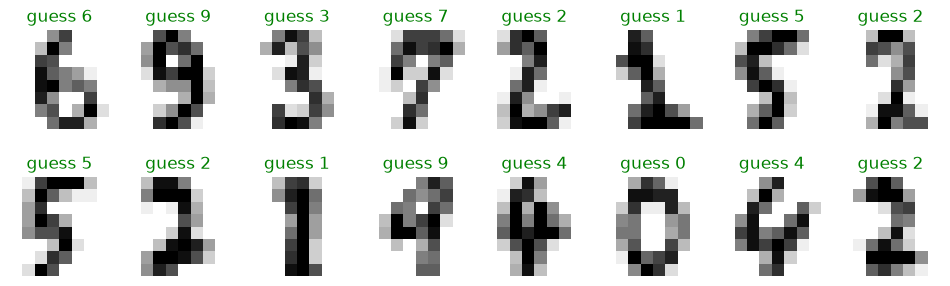

In [7]:
from sklearn.datasets import load_digits               # the handwritten digits pictures (Example 2)
# 1. data (pixels 0..1) + split
digits = load_digits()                          # 1797 small pictures (8 × 8 pixels) of handwritten digits
X = digits.data / 16                            # 64 pixels per picture. Pixels are 0 (white) .. 16 (black) → /16 makes them 0..1
y = digits.target                               # the real digit (0 to 9) for each picture
print("X:", X.shape, "  y:", y.shape)           # (1797, 64) and (1797,)

X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, random_state=42)            # take out the final exam (20%)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, random_state=42) # rest → homework (60%) + mock exam (20%)

X_train_t = to_tensor(X_train)                  # pixels → decimal tensors (float32)
X_val_t = to_tensor(X_val)
X_test_t = to_tensor(X_test)
y_train_t = to_tensor(y_train, torch.long)      # answers → WHOLE numbers (long): a class number 0..9, not a decimal
y_val_t = to_tensor(y_val, torch.long)          #   CrossEntropyLoss wants the class number like this

# 2. build + train
torch.manual_seed(42)                           # the same random start for everyone
digit_model = Net(n_inputs=64, n_hidden=32, n_outputs=10)   # 64 pixels → 32 hidden (ReLU) → 10 scores, one per digit
digit_trainer = Trainer(digit_model, nn.CrossEntropyLoss(), lr=0.01)   # CrossEntropyLoss: the loss for choosing a class (see below)
digit_trainer.fit(X_train_t, y_train_t, X_val_t, y_val_t, epochs=100)  # the same 5-line loop inside fit()

# 3. final exam: biggest score = the guess
scores = digit_trainer.predict(X_test_t)        # 10 scores for every test picture, shape (360, 10)

guesses = scores.argmax(dim=1).numpy()          # argmax = position of the biggest score in each row = the guessed digit

accuracy = (guesses == y_test).mean() * 100     # True = 1, False = 0 → the mean is the share of right guesses
print("Final exam accuracy:", round(accuracy, 1), "%")

# 4. look at 16 answers (green = right, red = wrong)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))               # 2 rows × 8 small pictures
for i, ax in enumerate(axes.flat):                              # .flat = go through all 16 boxes, one by one
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray_r")           # 64 numbers back into an 8 × 8 picture
    color = "green" if guesses[i] == y_test[i] else "red"       # right → green, wrong → red
    ax.set_title(f"guess {guesses[i]}", color=color)
    ax.axis("off")                                              # hide the axis numbers
plt.show()

### Why `CrossEntropyLoss`, not `MSELoss`?

**What does the network give?** For each picture: **10 scores**, one for each digit 0 … 9. The biggest score = the guess.

**What does `CrossEntropyLoss` do?** 2 small steps:
1. **softmax:** turn the 10 scores into **10 chances** that add up to 100%.
2. Look **only at the chance of the right digit**. Loss = −log(that chance).

| Chance given to the right digit | Loss | Meaning |
|---|---|---|
| 0.90 (90%) | **0.11** | sure and right → small loss ✓ |
| 0.50 (50%) | **0.69** | not sure → medium loss |
| 0.10 (10%) | **2.30** | almost sure of a wrong digit → big loss ✗ |
| 0.01 (1%) | **4.61** | very sure and wrong → very big loss ✗✗ |

So the network learns: **give the right digit a big chance.**

**Why not `MSELoss`?**
- MSE is for **numbers**, like marks or prices. 52 is close to 55, so a small error is OK.
- Digits here are **groups (classes)**, not amounts. A "7" is not "a bit more than a 6". If the network guessed **6.5** for a 7, that means nothing.
- With MSE, guessing a **1** for a **7** would be "more wrong" than guessing a **6**. But both are simply **wrong**.
- `CrossEntropyLoss` does not care about the size of the digit. It only asks: **how much chance did you give the right one?** And it punishes a **sure, wrong** guess the most.

| Problem | Answer | Loss |
|---|---|---|
| Maths mark, house price | a **number** | `nn.MSELoss()` |
| Which digit, spam or not | a **class** | `nn.CrossEntropyLoss()` |

(Remember Logistic Regression in Class 19: it also gives a **chance**, not a number. Same idea.)

# 🧑‍🏫 Example 3: approve a loan? (2 hidden layers + sigmoid)

**The problem:** the bank from Class 19 wants a yes/no answer: **approve** this loan or **not**?

**What is new:**
- **2 hidden layers** instead of 1. The first layer finds simple patterns, the second layer **mixes** them into bigger patterns.
- **Sigmoid** at the end: it turns the last number into a **chance from 0 to 1**. Chance above 0.5 → approve.

```
  4 inputs              hidden layer 1       hidden layer 2       output
  (the facts)           (8 neurons, ReLU)    (4 neurons, ReLU)    (1 neuron, Sigmoid)

  income       ──┐
  loan_amount  ──┼────▶  ( ) × 8  ────────▶  ( ) × 4  ────────▶  ( ) ──▶ chance of "approved"
  years_in_job ──┤
  defaulted    ──┘
```

**The rule for the sizes:** the output of one layer = the input of the next: `(4, 8)` → `(8, 4)` → `(4, 1)`.

| | Maths marks | Digits | Loan (today) |
|---|---|---|---|
| Answer | a number | 1 of 10 classes | **yes / no** |
| Last activation | none | none (softmax is inside the loss) | **Sigmoid** |
| Loss | `nn.MSELoss` | `nn.CrossEntropyLoss` | **`nn.BCELoss`** (Binary Cross Entropy: cross entropy for 2 classes) |

Sequential(
  (0): Linear(in_features=4, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=4, bias=True)
  (3): ReLU()
  (4): Linear(in_features=4, out_features=1, bias=True)
  (5): Sigmoid()
)
Weights + biases to learn: 81


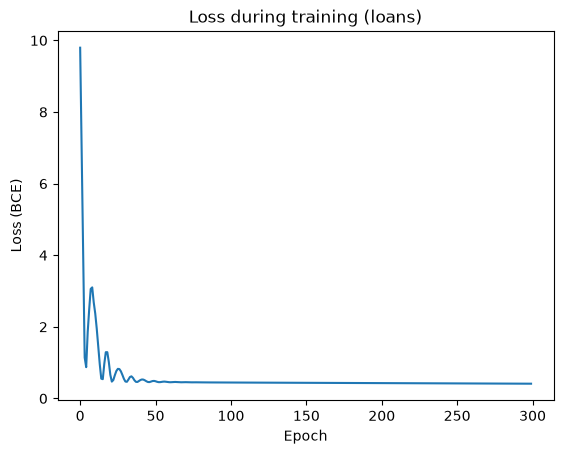

Test accuracy: 86.2 %
[200.0, 20.0, 10.0, 0.0] → chance of approval: 86 %
[50.0, 40.0, 1.0, 1.0] → chance of approval: 3 %


In [8]:
# 1. inputs and real answers
loans = pd.read_csv("loans.csv")                        # the same 400 people from Class 19
loans["income_k"] = loans["monthly_income"] / 1000      # 249000 → 249: make the big numbers small (like /16 for pixels)
X = loans[["income_k", "loan_amount", "years_in_job", "has_defaulted_before"]].values   # 4 inputs
y = loans["approved"].values                            # 1 = approved, 0 = not approved

# 2. split: train (80%) / test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)  # stratify: same % of yes in both
X_train_t = to_tensor(X_train)                          # inputs → decimal tensors
X_test_t = to_tensor(X_test)
y_train_t = to_tensor(y_train).reshape(-1, 1)           # answers as decimals 0.0 / 1.0, one column (BCELoss wants this)

# 3. the map: 4 inputs → 8 hidden → 4 hidden → 1 output
torch.manual_seed(42)                                   # the same random start for everyone
loan_model = nn.Sequential(
    nn.Linear(4, 8),                                    # hidden layer 1: 4 inputs → 8 neurons (32 weights + 8 biases)
    nn.ReLU(),                                          #   activation: negative → 0
    nn.Linear(8, 4),                                    # hidden layer 2: 8 → 4 neurons (32 weights + 4 biases)
    nn.ReLU(),                                          #   activation: negative → 0
    nn.Linear(4, 1),                                    # output: 4 → 1 neuron (4 weights + 1 bias)
    nn.Sigmoid(),                                       # squeeze into a chance from 0 to 1: 1 / (1 + e^(-z))
)
print(loan_model)
print("Weights + biases to learn:", sum(p.numel() for p in loan_model.parameters()))   # 40 + 36 + 5 = 81

loss_fn = nn.BCELoss()                                  # Binary Cross Entropy: right answer gets a high chance → small loss
optimizer = torch.optim.Adam(loan_model.parameters(), lr=0.01)

# 4. training loop: the same 5 lines
losses = []
for epoch in range(300):
    chance = loan_model(X_train_t)                      # 1. guess: a chance for every person
    loss = loss_fn(chance, y_train_t)                   # 2. how wrong
    optimizer.zero_grad()                               # 3. clear old gradients
    loss.backward()                                     # 4. backprop: a gradient for all 81 weights, in BOTH hidden layers
    optimizer.step()                                    # 5. one step downhill
    losses.append(loss.item())

plt.plot(losses)                                        # the loss should go DOWN
plt.title("Loss during training (loans)")
plt.xlabel("Epoch")
plt.ylabel("Loss (BCE)")
plt.show()

# 5. final exam: chance above 0.5 → approved (like Logistic Regression)
with torch.no_grad():                                   # only guessing, no learning
    test_chance = loan_model(X_test_t).numpy().ravel()  # one chance per test person, as a flat list
guesses = (test_chance > 0.5).astype(int)               # True/False → 1/0
print("Test accuracy:", round((guesses == y_test).mean() * 100, 1), "%")

# 6. use it: 2 new people
new_people = to_tensor([[200, 20, 10, 0],               # income 200k, loan 20, 10 years in job, never defaulted
                        [50, 40, 1, 1]])                # income 50k, loan 40, 1 year in job, defaulted before
with torch.no_grad():
    for person, c in zip(new_people, loan_model(new_people).ravel()):
        print(person.tolist(), "→ chance of approval:", round(c.item() * 100), "%")

**What we see:**
- The loss goes down: the 2 hidden layers learn together. `loss.backward()` finds the gradients for **both** layers at once.
- The first person gets a **high** chance, the second a **very low** one. That makes sense.
- Test accuracy is about **86%**, the **same as Logistic Regression** in Class 19. A simple table again → a simple model is enough. More layers help on photos, sound and text.

**Sigmoid: where to use it?**
- At the **end**, for a **yes/no** answer (with `nn.BCELoss`). ✓
- Inside the hidden layers we use **ReLU**: it learns faster. (Sigmoid in hidden layers was used in old networks.)

### ✏️ QUICK CHECK 5
1. Add a **third** hidden layer: `nn.Linear(4, 4), nn.ReLU()`. How many weights + biases now? Does the accuracy change?
2. Remove `nn.Sigmoid()` and run again. What error do you get? Why?

# 🏠 Home Problem: guess the price of a used car

Use the **same `Net` and `Trainer` classes**. Do not write them again!

Data: `cars.csv`. Inputs: `car_age`, `km_thousands`, `engine_cc`. Answer: `price_lakh`.

**Steps** (copy the Class Problem cell and change it):
1. Load the data, split 60 / 20 / 20 with `random_state=42`.
2. Scale, then make tensors.
3. `Net(3, 3, 1)`, `nn.MSELoss()`, `lr=0.1`, 300 epochs.
4. Draw the loss curves with `trainer.plot()`.
5. Calculate the test MAE: on average, how many lakh is it wrong?
6. Guess the price of a **5-year-old** car, **60 thousand km**, **1300 cc**.

In [9]:
# Write your code here

# Key Takeaways

- Training loop: **guess → how wrong → clear → blame (`loss.backward()`) → fix (`optimizer.step()`)**.
- `class Net(nn.Module)`: `__init__` builds the layers, `forward` is the forward pass.
- `class Trainer`: keeps model + loss + optimizer together. `fit` = training loop, `predict` = guess.
- **Write once, use many times:** the same classes work for marks, digits and cars.
- **More hidden layers:** add `nn.Linear` + `nn.ReLU` pairs. The output size of one layer = the input size of the next.
- **Yes/no answer:** `nn.Sigmoid()` at the end + `nn.BCELoss()`. Chance above 0.5 → yes.